In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Threshold of a distance-$d$ code under bit-flip circuit-level noise vs code distance. As in Fig. 6, the threshold of a distance-$d$ code is the physical error rate at which the code failure rates of $d$ and $d+2$ intersect. The threshold fit in `../Fig-threshold-fit` uses the same data. The thresholds it fits (`../Fig-threshold-fit/fitted_thresholds.csv`) are shown as dashed lines.

Run the following commands for generating the data.

```bash
python simulations/bit_flip_cln/logical_error_rate_gsm.py --distances 3 5 7 9 11 13 15 17 19 --error-rates 0.010 0.0181 0.0005 --shots 500000 --no-post-processing --output simulations/bit_flip_cln/Fig-threshold-crossings/data/gsm.csv
python simulations/bit_flip_cln/logical_error_rate_gsm.py --distances 3 5 7 9 11 13 15 17 19 --error-rates 0.011 0.0186 0.0005 --shots 500000 --output simulations/bit_flip_cln/Fig-threshold-crossings/data/gsm_pp.csv

python simulations/bit_flip_cln/logical_error_rate_ism.py --distances 3 5 7 9 11 13 15 17 19 --error-rates 0.005 0.0171 0.0005 --shots 500000 --no-post-processing --output simulations/bit_flip_cln/Fig-threshold-crossings/data/ism.csv
python simulations/bit_flip_cln/logical_error_rate_ism.py --distances 3 5 7 9 11 13 15 17 19 --error-rates 0.010 0.0181 0.0005 --shots 500000 --output simulations/bit_flip_cln/Fig-threshold-crossings/data/ism_pp.csv
```

In [2]:
DATA_DIR = Path("data")
DECODERS = {"gsm_pp": "MWPM+PP", "gsm": "MWPM", "ism_pp": "ISM+PP", "ism": "ISM"}

# one csv per decoder, as written by the commands above
data = {decoder: pd.read_csv(DATA_DIR / f"{decoder}.csv") for decoder in DECODERS}

In [3]:
def binomial_sigma(curve):
    """
    Standard deviation of the estimated code failure rates. Points without any failures (or successes)
    count half a failure (success), so they keep a finite weight.
    """
    n = curve["num_shots"].to_numpy()
    p = np.clip(curve["p_log"].to_numpy(), 0.5 / n, 1 - 0.5 / n)
    return np.sqrt(p * (1 - p) / n)


def find_crossing(df, d_small, d_large, half_width=3):
    """
    Physical error rate at which the code failure rates of d_small and d_large intersect, or nan if they
    don't intersect inside the simulated range.

    On the p_phys values of both curves, delta = p_log(d_large) - p_log(d_small) goes from negative
    (below threshold the larger code is better) to positive. Statistical noise can add further sign
    changes, especially far below threshold where both failure rates are almost zero, so we take the
    sign change best supported by the data: the one maximizing -sum_{j<=i} z_j + sum_{j>i} z_j, with
    z = delta / sigma(delta). The crossing is the root of a weighted quadratic fitted to delta over the
    half_width points on each side of that sign change.
    """
    a = df[df["distance"] == d_small].set_index("p_phys")
    b = df[df["distance"] == d_large].set_index("p_phys")
    p = np.array(sorted(a.index.intersection(b.index)))
    a, b = a.loc[p], b.loc[p]
    delta = b["p_log"].to_numpy() - a["p_log"].to_numpy()
    sigma = np.hypot(binomial_sigma(a), binomial_sigma(b))

    sign_changes = np.where((delta[:-1] < 0) & (delta[1:] >= 0))[0]
    if len(sign_changes) == 0:
        return np.nan
    z = delta / sigma
    support = [-z[: i + 1].sum() + z[i + 1:].sum() for i in sign_changes]
    i = sign_changes[np.argmax(support)]

    window = slice(max(0, i - half_width + 1), i + half_width + 1)
    p_mid = p[window].mean()  # centred for a well-conditioned fit
    deg = 2 if len(p[window]) >= 4 else 1
    fit = np.polynomial.Polynomial.fit(p[window] - p_mid, delta[window], deg, w=1 / sigma[window]).convert()
    roots = fit.roots()
    roots = roots[np.isreal(roots)].real + p_mid
    if len(roots) == 0:
        return np.nan
    return roots[np.argmin(np.abs(roots - (p[i] + p[i + 1]) / 2))]


def bootstrap_crossing(df, d_small, d_large, num_resamples=500, seed=0):
    """
    Standard deviation of the crossing of d_small and d_large over parametric bootstrap resamples, in
    which the number of failures of every point is redrawn from Binomial(num_shots, p_log).
    """
    rng = np.random.default_rng(seed)
    pair = df[df["distance"].isin([d_small, d_large])]
    crossings = []
    for _ in range(num_resamples):
        resample = pair.copy()
        resample["p_log"] = rng.binomial(pair["num_shots"], pair["p_log"]) / pair["num_shots"]
        crossings.append(find_crossing(resample, d_small, d_large))
    return np.nanstd(crossings)

In [4]:
rows = []
for decoder in DECODERS:
    df = data[decoder]
    distances = sorted(df["distance"].unique())
    for d_small, d_large in zip(distances[:-1], distances[1:]):
        p_th = find_crossing(df, d_small, d_large)
        if np.isnan(p_th):
            continue
        rows.append(dict(decoder=decoder, d=d_small, p_th=p_th, p_th_err=bootstrap_crossing(df, d_small, d_large)))
thresholds = pd.DataFrame(rows)
thresholds

,decoder,d,p_th,p_th_err
0,gsm_pp,3,0.012426,0.000051
1,gsm_pp,5,0.014704,0.000053
2,gsm_pp,7,0.015513,0.000044
3,gsm_pp,9,0.015857,0.000047
4,gsm_pp,11,0.016047,0.000054
5,gsm_pp,13,0.016185,0.000044
6,gsm_pp,15,0.016332,0.000042
7,gsm_pp,17,0.016399,0.000037
8,gsm,3,0.011379,0.000062
9,gsm,5,0.014463,0.000051


Check of the crossings: the code failure rates of $d$ and $d+2$ around each crossing, with the crossing (dashed) and its bootstrap error (gray).

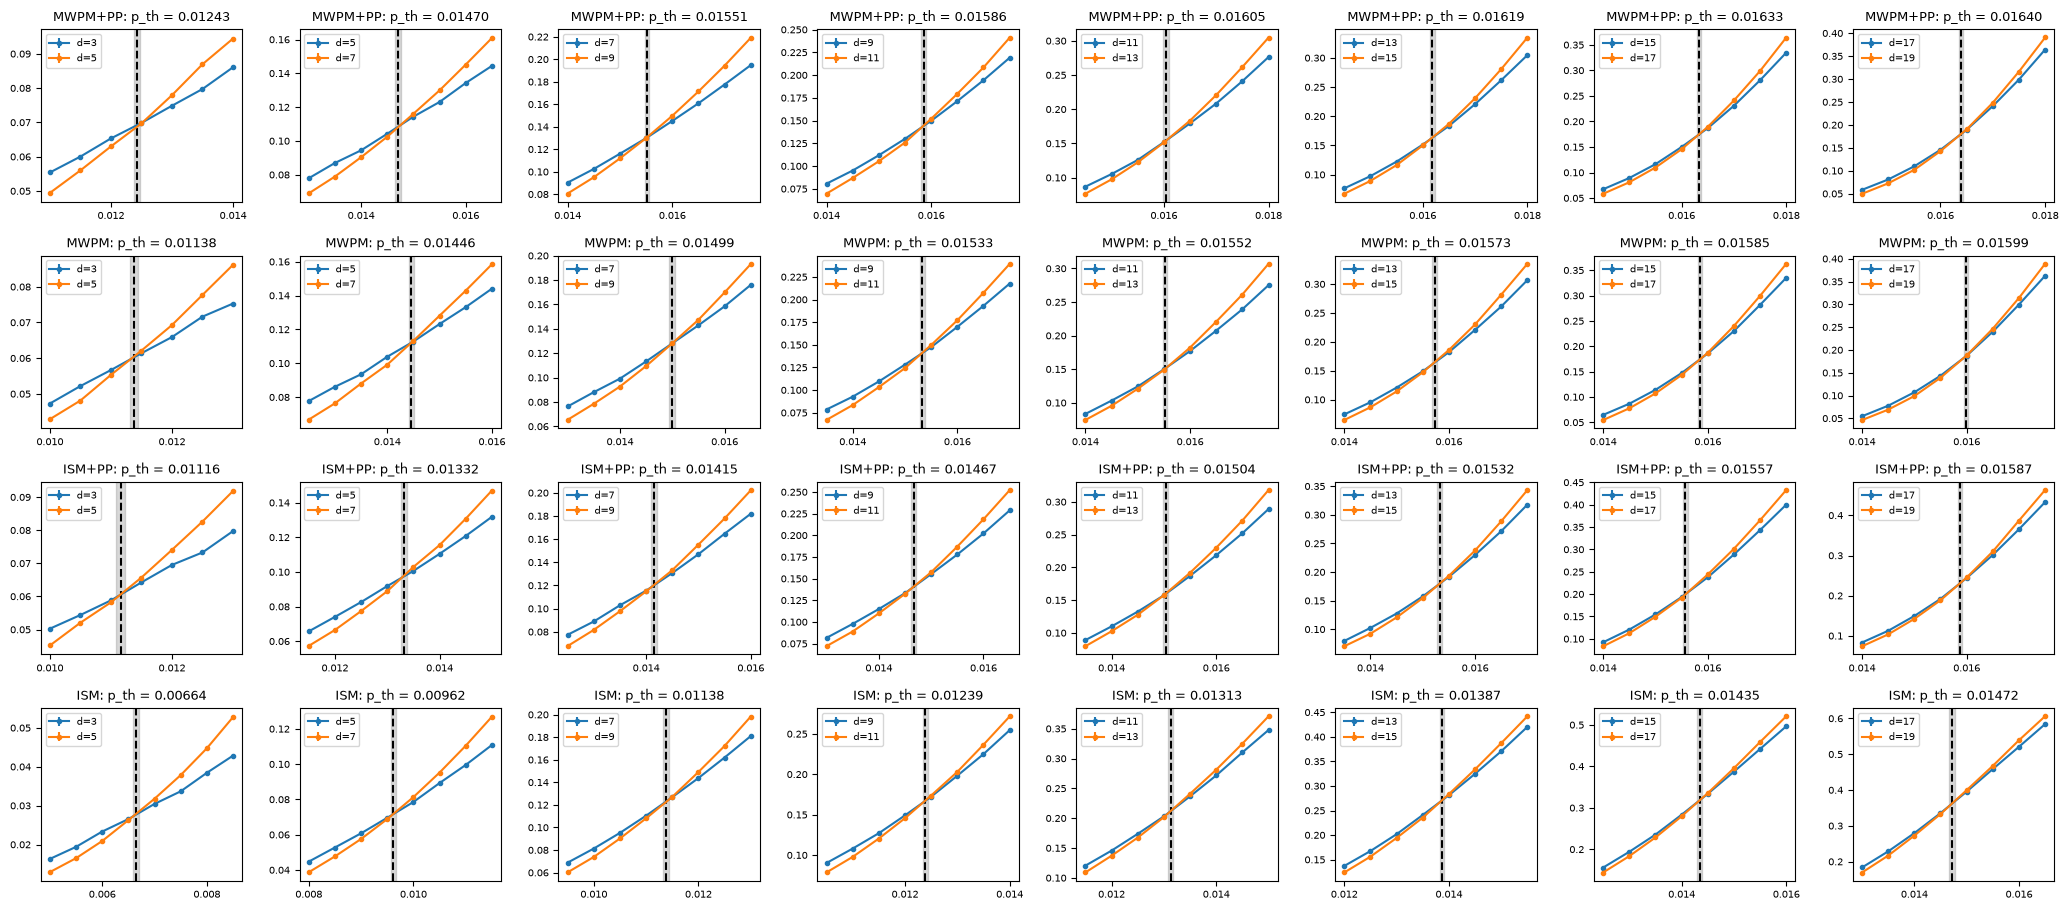

In [5]:
pairs = sorted(thresholds["d"].unique())
fig, axes = plt.subplots(len(DECODERS), len(pairs), figsize=(2.6 * len(pairs), 2.3 * len(DECODERS)))
for row, decoder in zip(axes, DECODERS):
    df = data[decoder]
    for ax, d_small in zip(row, pairs):
        t = thresholds[(thresholds["decoder"] == decoder) & (thresholds["d"] == d_small)]
        if t.empty:
            ax.set_axis_off()
            continue
        t = t.iloc[0]
        for d in (d_small, d_small + 2):
            curve = df[(df["distance"] == d) & ((df["p_phys"] - t["p_th"]).abs() <= 0.002)]
            ax.errorbar(curve["p_phys"], curve["p_log"], yerr=binomial_sigma(curve), fmt="o-", markersize=3,
                        label=f"d={d}")
        ax.axvline(t["p_th"], color="black", linestyle="dashed")
        ax.axvspan(t["p_th"] - t["p_th_err"], t["p_th"] + t["p_th_err"], color="gray", alpha=0.3)
        ax.set_title(f"{DECODERS[decoder]}: p_th = {t['p_th']:.5f}", fontsize=9)
        ax.tick_params(labelsize=7)
        ax.locator_params(axis="x", nbins=3)
        ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

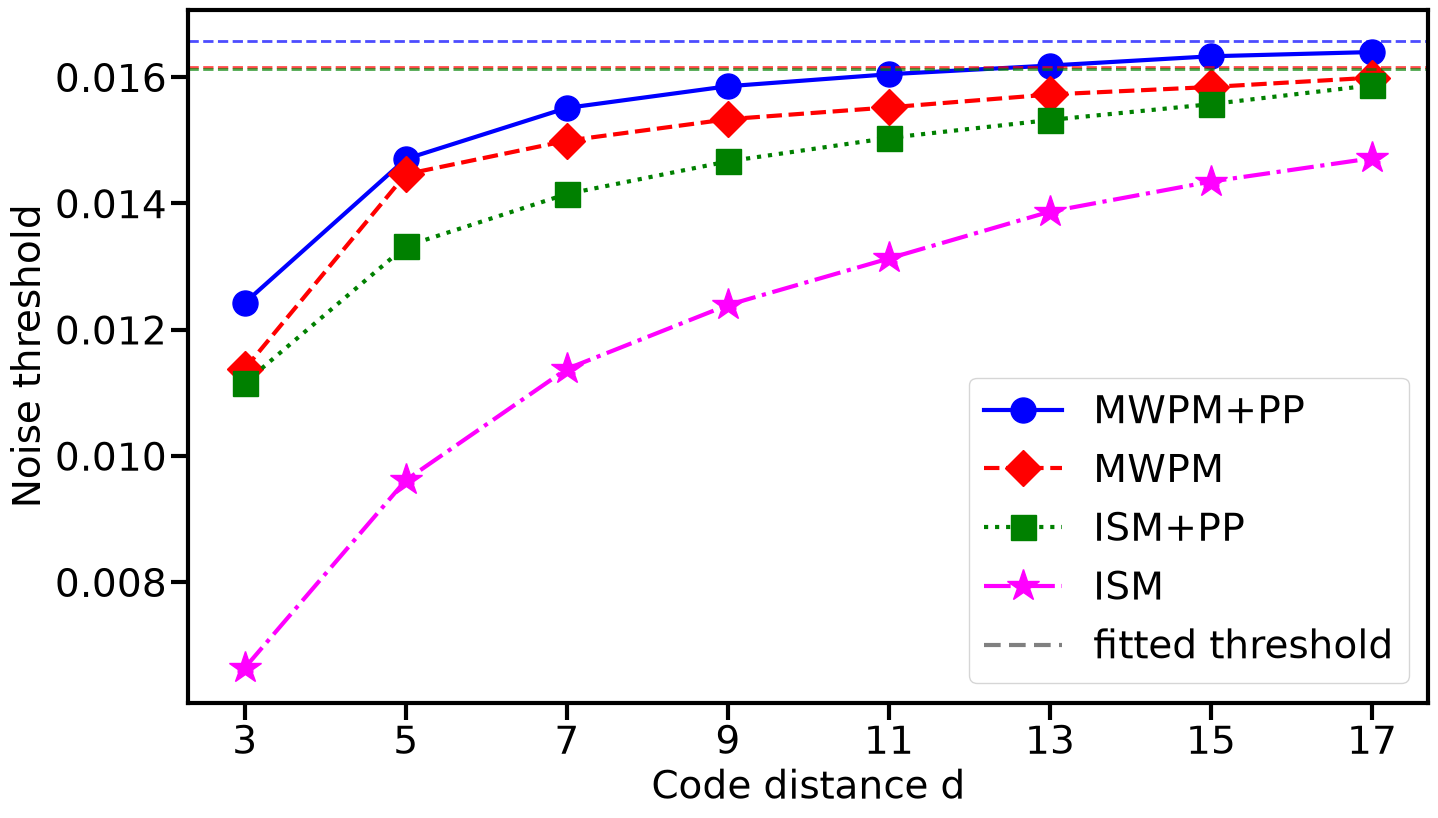

In [6]:
STYLES = {
    "MWPM+PP": dict(color='blue',    linestyle='solid',   marker='o', markersize=18),
    "MWPM":    dict(color='red',     linestyle='dashed',  marker='D', markersize=18),
    "ISM+PP":  dict(color='green',   linestyle='dotted',  marker='s', markersize=18),
    "ISM":     dict(color='magenta', linestyle='dashdot', marker='*', markersize=24),
}

def plot_thresholds(thresholds, ax, fitted=None, save_path=None):
    for decoder, label in DECODERS.items():
        t = thresholds[thresholds["decoder"] == decoder]
        ax.plot(t["d"], t["p_th"], label=label, linewidth=3, **STYLES[label])
        # 1 sigma bootstrap errors, about the size of the markers
        ax.errorbar(t["d"], t["p_th"], yerr=t["p_th_err"], fmt="none", ecolor=STYLES[label]["color"],
                    elinewidth=2, capsize=6, capthick=2)
    # thresholds of the fits as dashed lines in the colour of the decoder; the dashes of the decoders are
    # shifted against each other, so that lines at (almost) the same threshold alternate their colours
    if fitted is not None:
        for k, (decoder, p_th) in enumerate(zip(fitted["decoder"], fitted["p_th"])):
            ax.axhline(p_th, color=STYLES[DECODERS[decoder]]["color"], linewidth=2, alpha=0.7, linestyle="--") #, linestyle=(4 * k, (4, 8)), zorder=1)
        ax.plot([], [], color="gray", linewidth=3, linestyle=(0, (4, 2)), label="fitted threshold")
        bottom, top = ax.get_ylim()
        #ax.set_ylim(bottom, top + 0.06 * (top - bottom))  # room above the lines
    ax.legend(loc="lower right", prop={"size": 28})
    ax.set_xticks(sorted(thresholds["d"].unique()))
    ax.tick_params(axis="both", labelsize=28)
    ax.set_xlabel("Code distance d", size=28)
    ax.set_ylabel("Noise threshold", size=28)
    # Thicker box around plot (spines)
    for spine in ax.spines.values():
        spine.set_linewidth(3)
    # Thicker major and minor ticks
    ax.tick_params(axis="both", which="major", width=3, length=12)
    ax.tick_params(axis="both", which="minor", width=1.5, length=8)
    if save_path is not None:
        ax.figure.savefig(save_path, format="pdf", bbox_inches="tight")
    plt.show()


FITTED = Path("../Fig-threshold-fit/fitted_thresholds.csv")  # written by the fit notebook
fitted = pd.read_csv(FITTED) if FITTED.exists() else None

fig, ax = plt.subplots(figsize=(16, 9))
plot_thresholds(thresholds, ax, fitted=fitted, save_path="./Fig-threshold-crossings.pdf")